# **Customer Analysis**

In [39]:
import pandas as pd
import numpy
import matplotlib.pyplot as plt
import plotly.express as px
import seaborn as sns
from matplotlib.ticker import FuncFormatter

In [40]:
pd.set_option('display.max_columns', None)
pd.set_option('display.float_format', '{:,.2f}'.format)

In [41]:
ecommerce_df = pd.read_csv(
    'dataset/processed/ecommerce_processed.csv',
    parse_dates=['order_date']
)

In [42]:
def currency_formatter(x, _):
    if x >= 1_000_000_000:
        val = x / 1e9
        return f'${val:.1f}B'.replace('.0B', 'B')
    elif x >= 1_000_000:
        val = x / 1e6
        return f'${val:.1f}M'.replace('.0M', 'M')
    elif x >= 1_000:
        val = x / 1e3
        return f'${val:.1f}K'.replace('.0K', 'K')
    else:
        return f'${x:,.0f}'

## 1. Load Only Relevant Columns

In [43]:
CUSTOMER_COLUMNS = [
    # Year
    'order_year',
    
    # CUSTOMER PROFILE
    'customer_name',
    'gender',
    'age',
    'age_group',
    'customer_segment',
    'country',

    # PURCHASE BEHAVIOR
    'quantity',
    'net_revenue_usd',
    'profit_usd',
    'profit_margin_percent',
    'order_value_segment',

    # LOYALTY
    'customer_loyalty_score',
    'loyalty_tier',

    # ENGAGEMENT
    'session_duration_min',
    'engagement_level',
    'pages_visited',

    # CUSTOMER JOURNEY
    'abandoned_cart_before',
    'coupon_used',

    # DEVICE / ACQUISITION
    'device_type',
    'traffic_source',
]

In [44]:
customer_df = ecommerce_df[CUSTOMER_COLUMNS].copy()

In [45]:
customer_df.sample(10)

,order_year,customer_name,gender,age,age_group,customer_segment,country,quantity,net_revenue_usd,profit_usd,profit_margin_percent,order_value_segment,customer_loyalty_score,loyalty_tier,session_duration_min,engagement_level,pages_visited,abandoned_cart_before,coupon_used,device_type,traffic_source
565853,2024,Brenda Cook,Female,46,45-54,Premium,United States,1,103.88,36.45,35.09,Medium,47.80,Medium,10.40,Low,3,Yes,No,Tablet,Search
180323,2024,Sarah Lowe,Female,18,18-24,Regular,Australia,4,167.51,51.79,30.92,Medium,63.60,Medium,15.30,Medium,9,Yes,Yes,Desktop,Direct
184871,2024,Erik Miranda Jr.,Male,71,65+,Regular,Germany,3,460.74,157.08,34.09,High,0.80,Low,20.80,Medium,14,No,No,Desktop,Search
554152,2025,Dorothy Tanner,Female,39,35-44,Regular,Belgium,5,241.49,101.84,42.17,Medium,20.10,Low,17.20,Medium,11,No,Yes,Tablet,Email
251938,2024,Andrea Martin,Female,31,25-34,Regular,United States,2,233.19,85.63,36.72,Medium,25.20,Low,54.90,High,3,No,No,Tablet,Direct
856849,2025,Carlos Perry DVM,Male,53,45-54,Regular,Belgium,4,378.76,110.84,29.26,High,57.70,Medium,58.70,High,19,Yes,No,Desktop,Email
255213,2024,Joseph Wise,Male,73,65+,Premium,United States,5,"1,020.40",457.90,44.87,Very High,55.80,Medium,38.20,Medium,15,No,Yes,Desktop,Search
116174,2024,Haley Black,Female,44,35-44,Premium,United States,5,418.92,113.77,27.16,High,7.00,Low,46.70,High,3,No,Yes,Tablet,Social
792894,2024,Melissa Perez,Female,73,65+,Regular,United States,3,365.26,112.93,30.92,High,84.20,High,28.10,Medium,15,No,No,Mobile,Search
103166,2025,Ryan Valencia,Male,55,55-64,Premium,Italy,4,381.52,107.88,28.28,High,48.10,Medium,26.10,Medium,19,No,No,Desktop,Search


## 2. Customer Overview

In [46]:
print(f"Total Transactions      :   {customer_df.shape[0]:,}")
print(f"Countries Covered       :   {customer_df['country'].nunique()}")
print(f"Customer Segments       :   {customer_df['customer_segment'].nunique()}")
print(f"Average Age             :   {customer_df['age'].mean():.2f}")
print(f"Average Loyalty         :   {customer_df['customer_loyalty_score'].mean():.2f}")

Total Transactions      :   1,000,123
Countries Covered       :   10
Customer Segments       :   3
Average Age             :   46.49
Average Loyalty         :   49.97


## 3. Customer Demographics

### 3.1 Customer Age Distribution

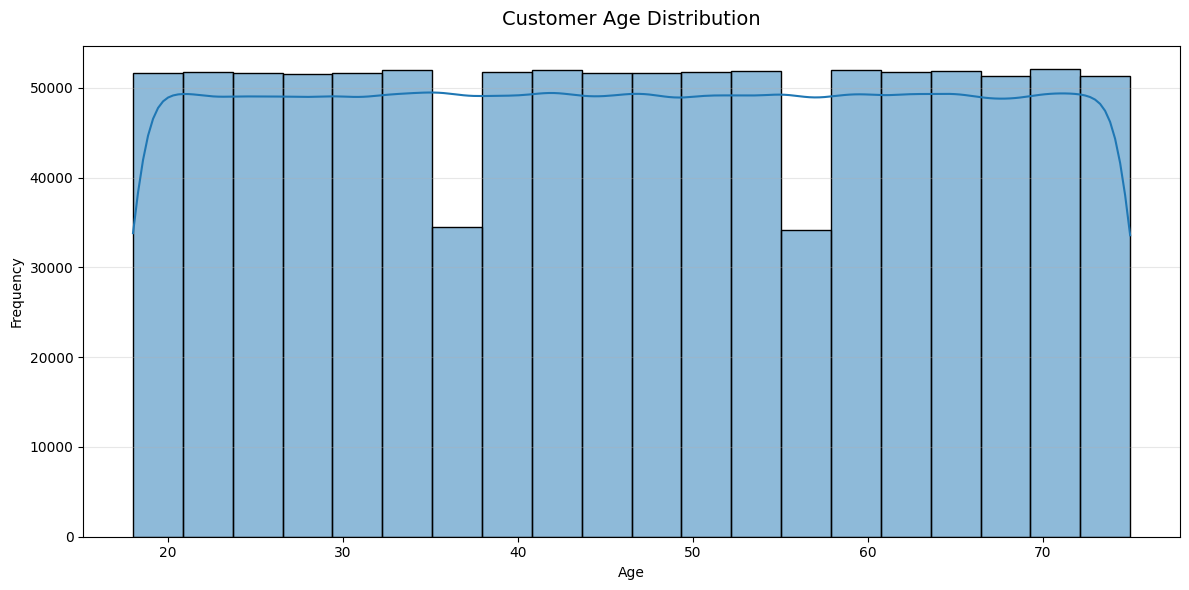

In [47]:
plt.figure(figsize=(12, 6))

ax = sns.histplot(
    data=customer_df,
    x='age',
    bins=20,
    kde=True
)

plt.title('Customer Age Distribution', fontsize=14, pad=15)
plt.xlabel('Age')
plt.ylabel('Frequency')
plt.grid(axis='y', alpha=0.3)
plt.tight_layout()
plt.show()

### 3.2 Average Transaction Value by Age Group

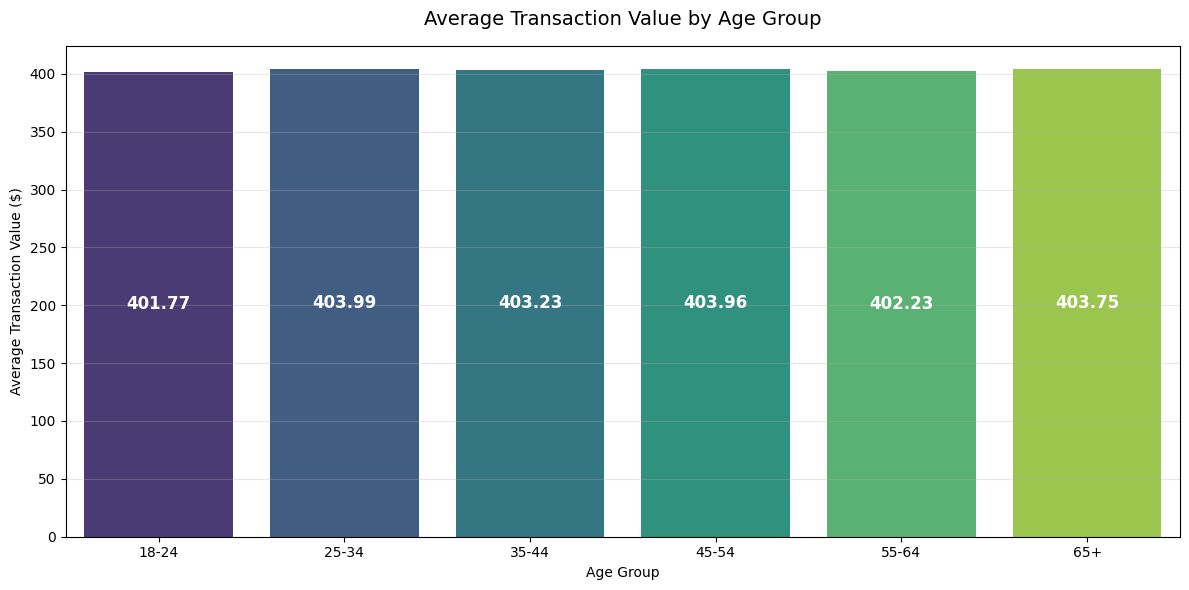

In [48]:
age_value = (
    customer_df
    .groupby('age_group', observed=True)
    .agg(
        avg_transaction_value=('net_revenue_usd', 'mean'),
        total_revenue=('net_revenue_usd', 'sum')
    )
    .reset_index()
)

plt.figure(figsize=(12, 6))

ax = sns.barplot(
    data=age_value,
    x='age_group',
    y='avg_transaction_value',
    palette='viridis',
    hue='age_group',
    legend=False
)

for container in ax.containers:
    ax.bar_label(
        container,
        labels=[f'{v:,.2f}' for v in container.datavalues],
        label_type='center',          
        color='white',
        fontsize=12,
        fontweight='bold'
    )

plt.title('Average Transaction Value by Age Group', fontsize=14, pad=15)
plt.xlabel('Age Group')
plt.ylabel('Average Transaction Value ($)')
plt.grid(axis='y', alpha=0.3)
plt.tight_layout()
plt.show()

### 3.3 Customer Transactions by Gender Across Year

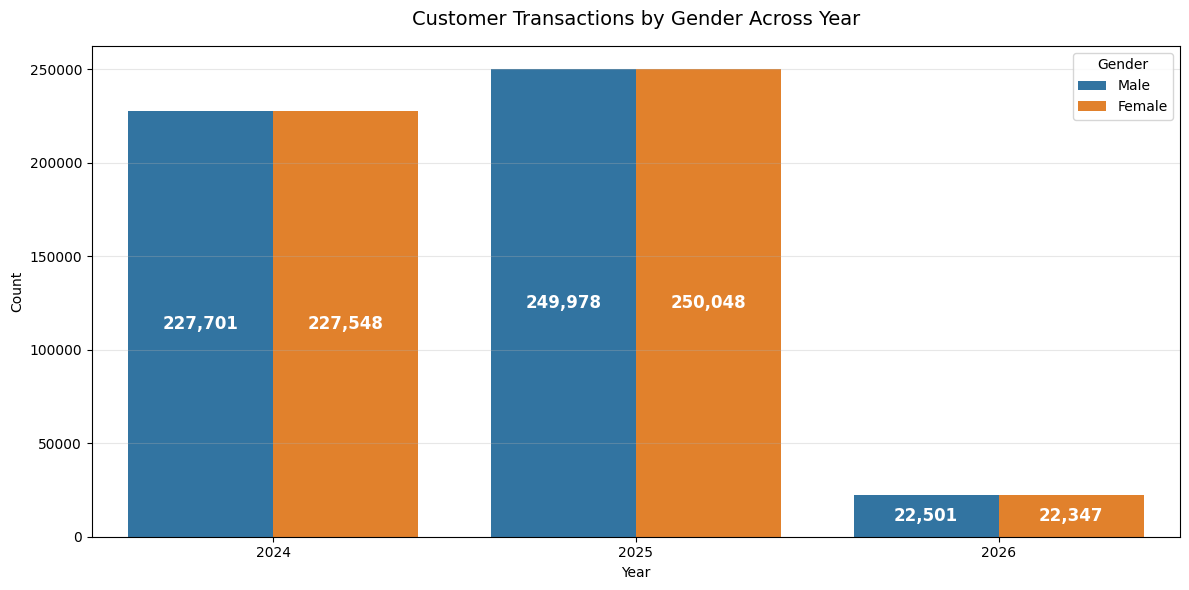

In [49]:
transaction_gender = (
    customer_df
    .groupby('order_year')['gender']
    .value_counts()
    .reset_index()
)

plt.figure(figsize=(12, 6))

ax = sns.barplot(
    data=transaction_gender,
    x='order_year',
    y='count',
    hue='gender'
)

for container in ax.containers:
    ax.bar_label(
        container,
        labels=[f'{v:,.0f}' for v in container.datavalues],
        label_type='center',          
        color='white',
        fontsize=12,
        fontweight='bold'
    )

plt.title('Customer Transactions by Gender Across Year', fontsize=14, pad=15)
plt.xlabel('Year')
plt.ylabel('Count')
plt.legend(title='Gender')
plt.grid(axis='y', alpha=0.3)
plt.tight_layout()
plt.show()

## 4. Customer Segment Analysis

### 4.1 Average Transaction Value by Customer Segment Across Year

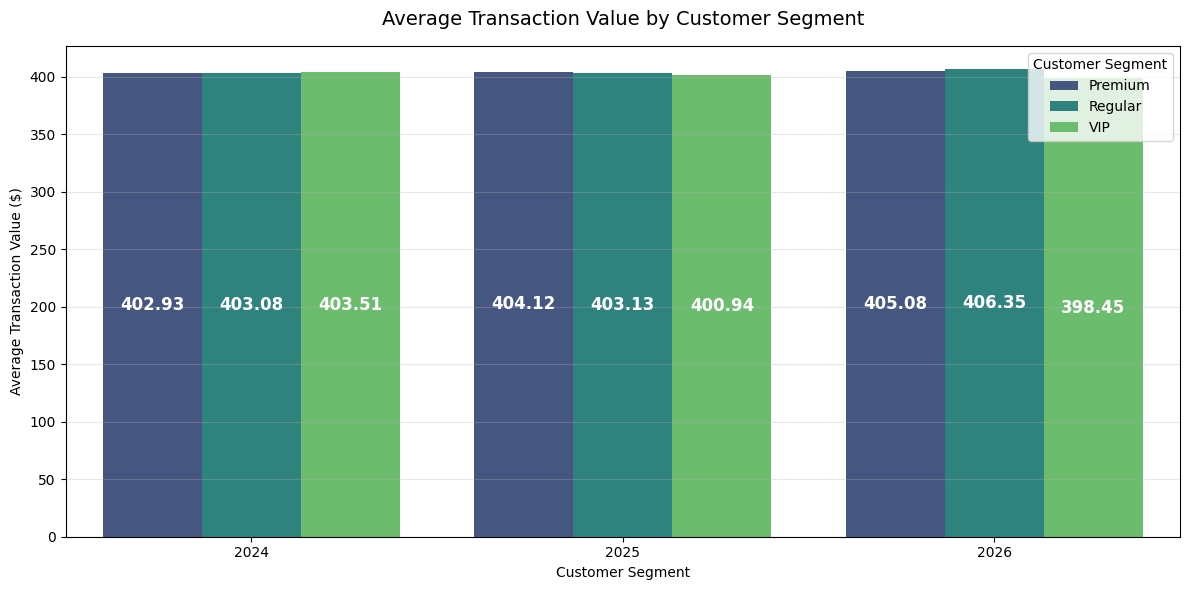

In [50]:
customer_value = (
    customer_df
    .groupby(['order_year', 'customer_segment'])
    .agg(
        avg_transaction_value=('net_revenue_usd', 'mean'),
        total_revenue=('net_revenue_usd', 'sum')
    )
    .reset_index()
)

plt.figure(figsize=(12, 6))

ax = sns.barplot(
    data=customer_value,
    x='order_year',
    y='avg_transaction_value',
    palette='viridis',
    hue='customer_segment',
)

for container in ax.containers:
    ax.bar_label(
        container,
        labels=[f'{v:,.2f}' for v in container.datavalues],
        label_type='center',          
        color='white',
        fontsize=12,
        fontweight='bold'
    )

plt.title('Average Transaction Value by Customer Segment', fontsize=14, pad=15)
plt.xlabel('Customer Segment')
plt.ylabel('Average Transaction Value ($)')
plt.legend(title='Customer Segment')
plt.grid(axis='y', alpha=0.3)
plt.tight_layout()
plt.show()

## 5. Customer Loyalty

### 5.1 Loyalty Tier Distribution by Customer Segment

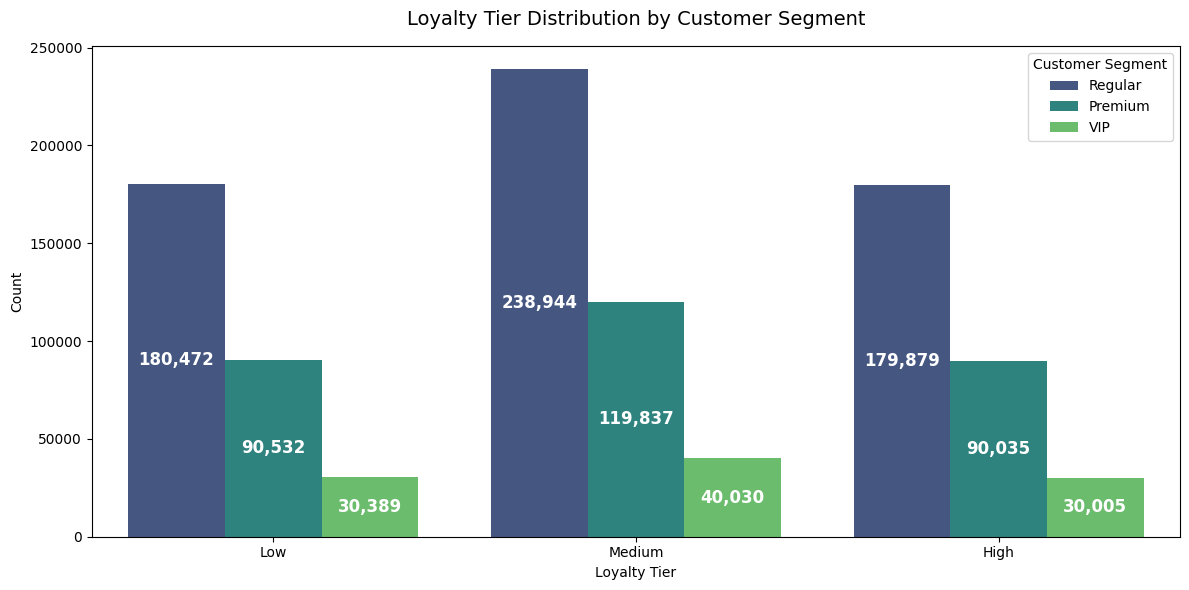

In [51]:
loyalty_tier_distribution = (
    customer_df
    .groupby(['customer_segment', 'loyalty_tier'])
    .size()
    .reset_index(name='count')
)

segment_order = ['Regular', 'Premium', 'VIP']
tier_order = ['Low', 'Medium', 'High']

loyalty_tier_distribution['customer_segment'] = pd.Categorical(
    loyalty_tier_distribution['customer_segment'],
    categories=segment_order,
    ordered=True
)
loyalty_tier_distribution['loyalty_tier'] = pd.Categorical(
    loyalty_tier_distribution['loyalty_tier'],
    categories=tier_order,
    ordered=True
)

loyalty_tier_distribution = loyalty_tier_distribution.sort_values(
    ['customer_segment', 'loyalty_tier']
)

plt.figure(figsize=(12, 6))

ax = sns.barplot(
    data=loyalty_tier_distribution,
    x='loyalty_tier',
    y='count',
    hue='customer_segment',
    palette='viridis'
)

for container in ax.containers:
    ax.bar_label(
        container,
        labels=[f'{v:,.0f}' for v in container.datavalues],
        label_type='center',          
        color='white',
        fontsize=12,
        fontweight='bold'
    )

plt.title('Loyalty Tier Distribution by Customer Segment', fontsize=14, pad=15)
plt.xlabel('Loyalty Tier')
plt.ylabel('Count')
plt.legend(title='Customer Segment')
plt.tight_layout()
plt.show()

### 5.2 Loyalty Score vs Transaction Value

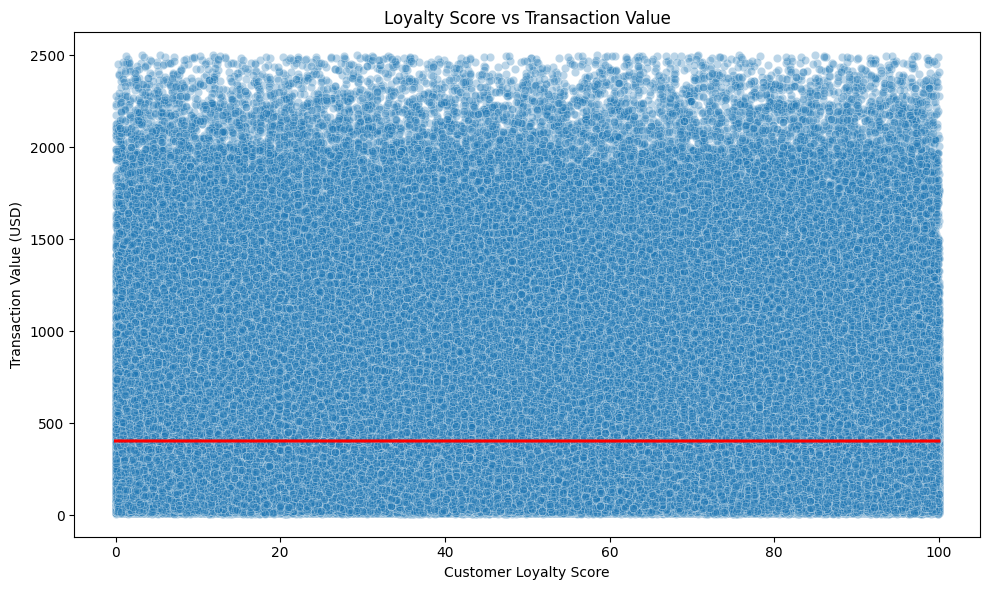

In [52]:


plt.figure(figsize=(10, 6))

sns.scatterplot(
    data=customer_df,
    x="customer_loyalty_score",
    y="net_revenue_usd",
    alpha=0.3
)

sns.regplot(
    data=customer_df,
    x="customer_loyalty_score",
    y="net_revenue_usd",
    scatter=False,
    color="red"
)

plt.title("Loyalty Score vs Transaction Value")
plt.xlabel("Customer Loyalty Score")
plt.ylabel("Transaction Value (USD)")
plt.tight_layout()
plt.show()

## 6. Customer Engagement

### 6.1 Engagement Level Distribution

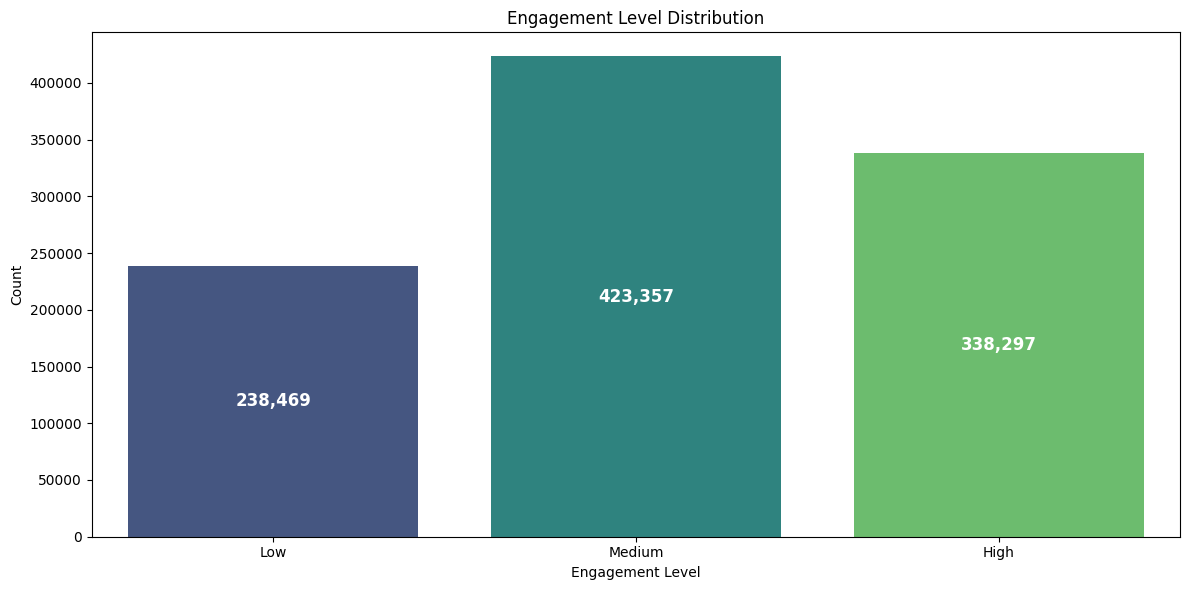

In [53]:
engagement_distribution = (
    customer_df['engagement_level']
    .value_counts()
    .reindex(['Low', 'Medium', 'High'])
    .reset_index()
)

plt.figure(figsize=(12, 6))

ax = sns.barplot(
    data=engagement_distribution,
    x='engagement_level',
    y='count',
    palette='viridis',
    hue='engagement_level',
    legend=False
)

for container in ax.containers:
    ax.bar_label(
        container,
        labels=[f'{v:,.0f}' for v in container.datavalues],
        label_type='center',          
        color='white',
        fontsize=12,
        fontweight='bold'
    )

plt.title("Engagement Level Distribution")
plt.xlabel("Engagement Level")
plt.ylabel("Count")
plt.tight_layout()
plt.show()

### 6.2 Engagement Level vs Transaction Value

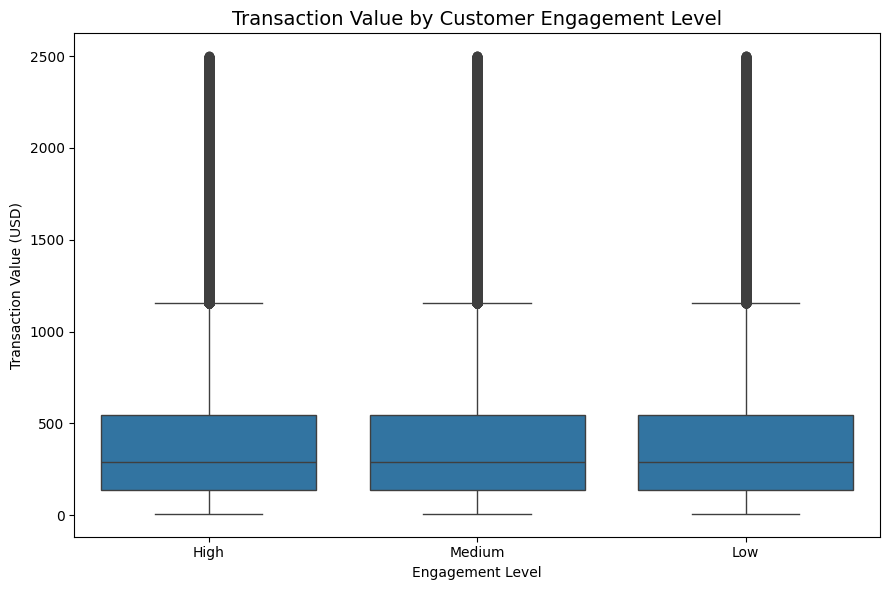

In [54]:
plt.figure(figsize=(9, 6))

sns.boxplot(
    data=customer_df,
    x='engagement_level',
    y='net_revenue_usd'
)

plt.title('Transaction Value by Customer Engagement Level', fontsize=14)
plt.xlabel('Engagement Level')
plt.ylabel('Transaction Value (USD)')

plt.tight_layout()
plt.show()

### 6.2 Session Engagement vs Purchase Quantity

C:\Users\User\AppData\Local\Temp\ipykernel_11456\517188316.py:16: UserWarning: Creating legend with loc="best" can be slow with large amounts of data.
  plt.tight_layout()
c:\Users\User\Desktop\gethub\Ecommerce-EDA-and-Sales-Prediction\.venv\lib\site-packages\IPython\core\pylabtools.py:170: UserWarning: Creating legend with loc="best" can be slow with large amounts of data.
  fig.canvas.print_figure(bytes_io, **kw)


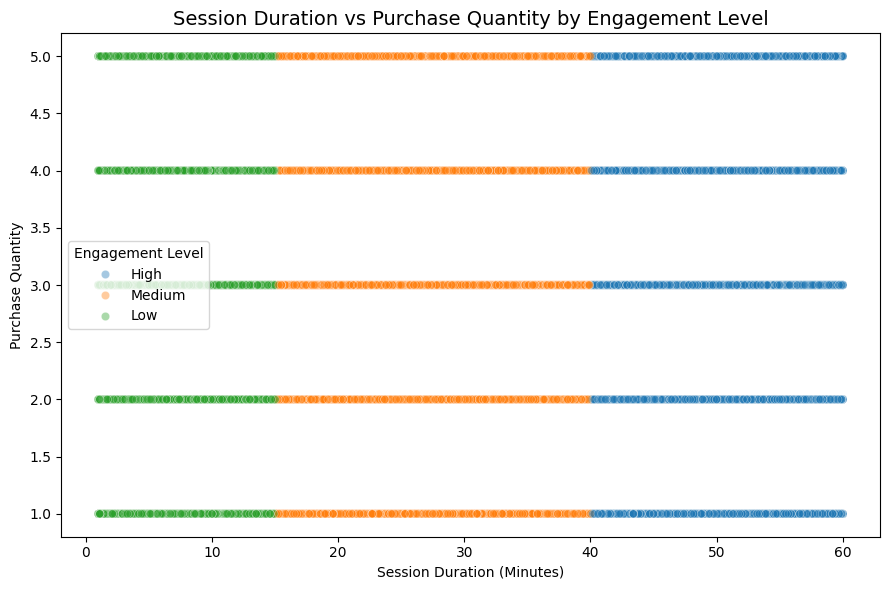

In [55]:
plt.figure(figsize=(9, 6))

sns.scatterplot(
    data=customer_df,
    x='session_duration_min',
    y='quantity',
    hue='engagement_level',
    alpha=0.4
)

plt.title('Session Duration vs Purchase Quantity by Engagement Level', fontsize=14)
plt.xlabel('Session Duration (Minutes)')
plt.ylabel('Purchase Quantity')
plt.legend(title='Engagement Level')

plt.tight_layout()
plt.show()

## 7. Purchase Behavior

### 7.1 Previous Cart Abandonment

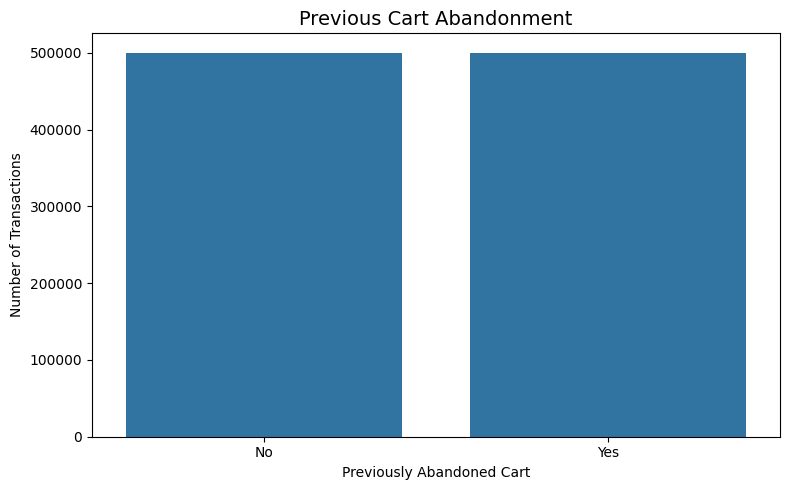

In [56]:
plt.figure(figsize=(8, 5))

sns.countplot(
    data=customer_df,
    x='abandoned_cart_before'
)

plt.title('Previous Cart Abandonment', fontsize=14)
plt.xlabel('Previously Abandoned Cart')
plt.ylabel('Number of Transactions')

plt.tight_layout()
plt.show()

### 7.2 Transaction Value by Cart Abandonment

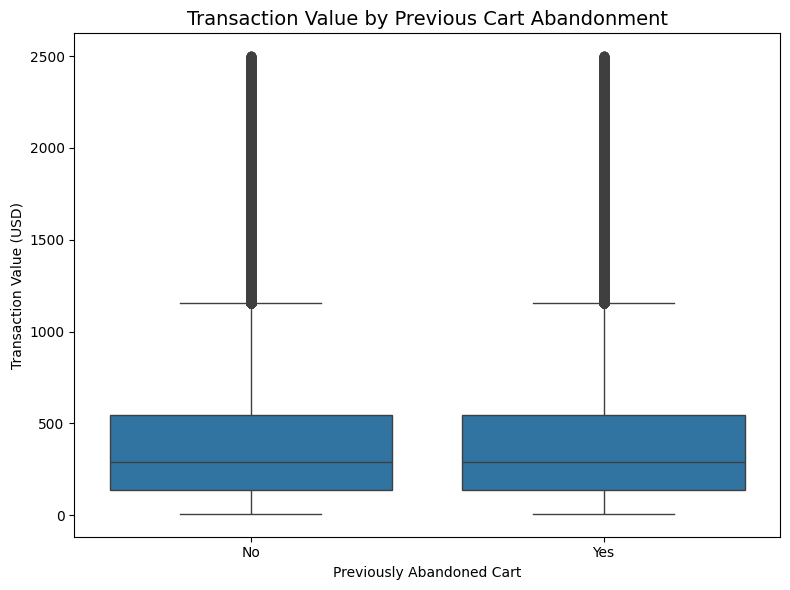

In [57]:
plt.figure(figsize=(8, 6))

sns.boxplot(
    data=customer_df,
    x='abandoned_cart_before',
    y='net_revenue_usd'
)

plt.title('Transaction Value by Previous Cart Abandonment', fontsize=14)
plt.xlabel('Previously Abandoned Cart')
plt.ylabel('Transaction Value (USD)')

plt.tight_layout()
plt.show()

### 7.3 Cart Abandonment and Profitability

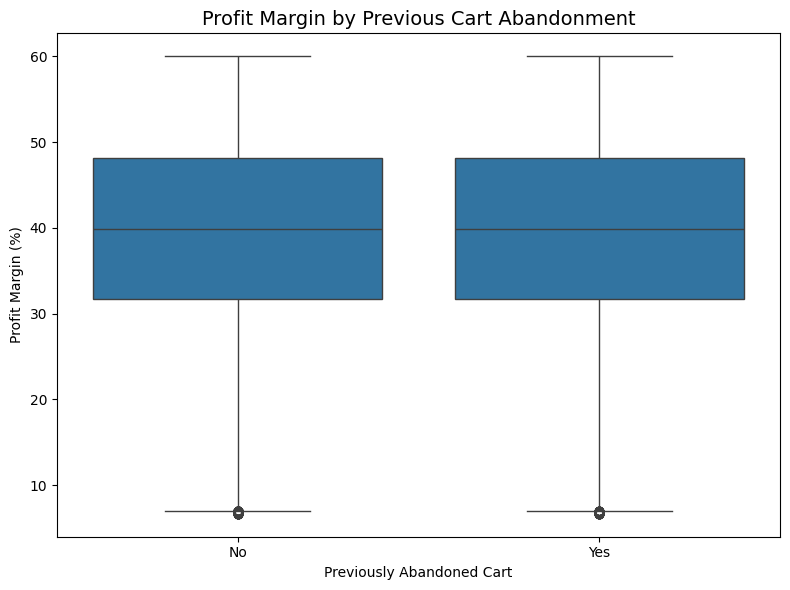

In [58]:
plt.figure(figsize=(8, 6))

sns.boxplot(
    data=customer_df,
    x='abandoned_cart_before',
    y='profit_margin_percent'
)

plt.title('Profit Margin by Previous Cart Abandonment', fontsize=14)
plt.xlabel('Previously Abandoned Cart')
plt.ylabel('Profit Margin (%)')

plt.tight_layout()
plt.show()

## 8. Customer Acquisition

### 8.1 Average Transaction Value by Traffic Source

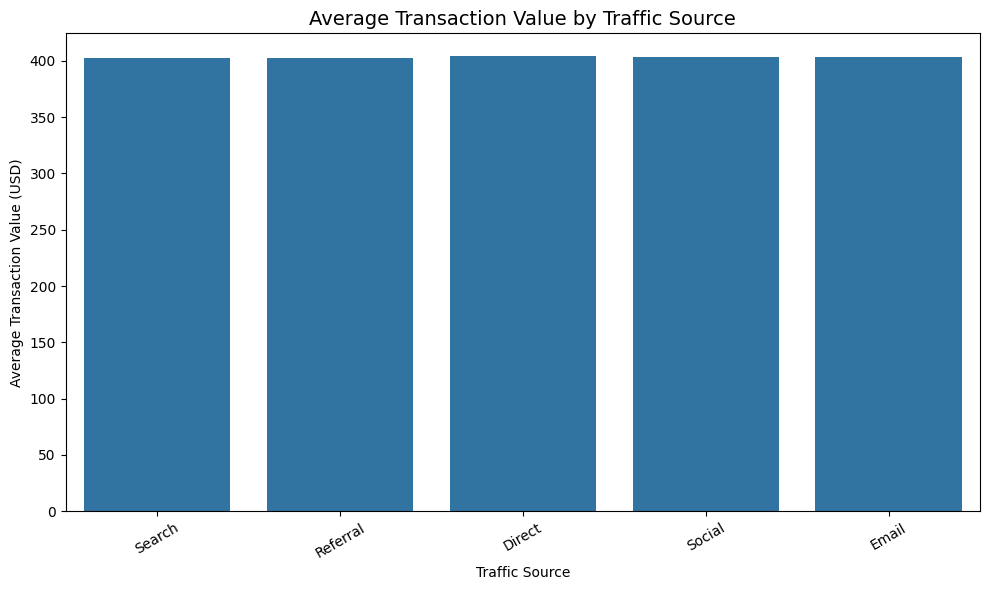

In [59]:
plt.figure(figsize=(10, 6))

sns.barplot(
    data=customer_df,
    x='traffic_source',
    y='net_revenue_usd',
    estimator='mean',
    errorbar=None
)

plt.title('Average Transaction Value by Traffic Source', fontsize=14)
plt.xlabel('Traffic Source')
plt.ylabel('Average Transaction Value (USD)')

plt.xticks(rotation=30)

plt.tight_layout()
plt.show()

### 8.2 Profitability by Traffic Source

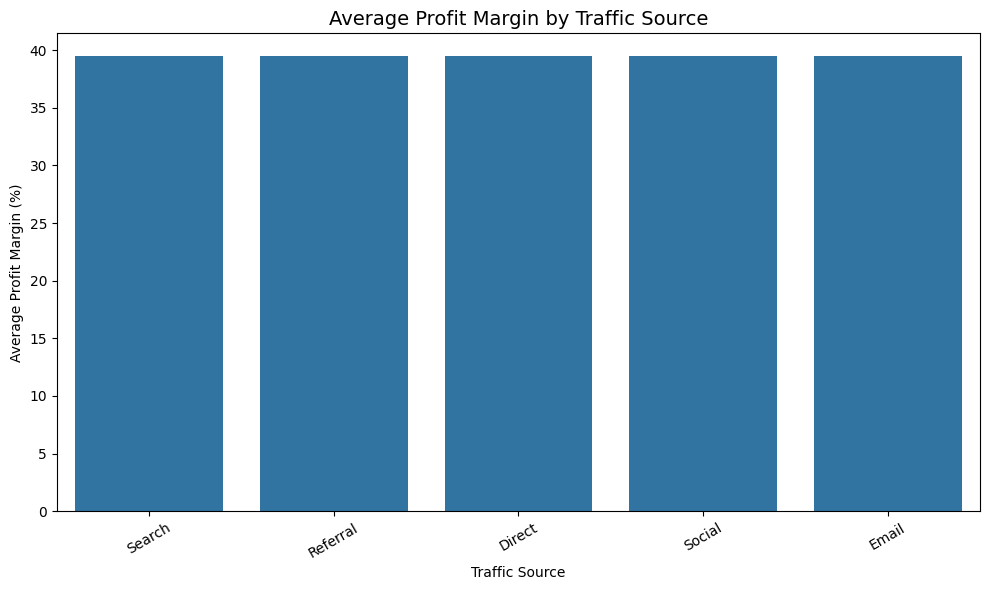

In [60]:
plt.figure(figsize=(10, 6))

sns.barplot(
    data=customer_df,
    x='traffic_source',
    y='profit_margin_percent',
    estimator='mean',
    errorbar=None
)

plt.title('Average Profit Margin by Traffic Source', fontsize=14)
plt.xlabel('Traffic Source')
plt.ylabel('Average Profit Margin (%)')

plt.xticks(rotation=30)

plt.tight_layout()
plt.show()

## 9. Customer Value

### 9.1 Customer Segment x Order Value Segment

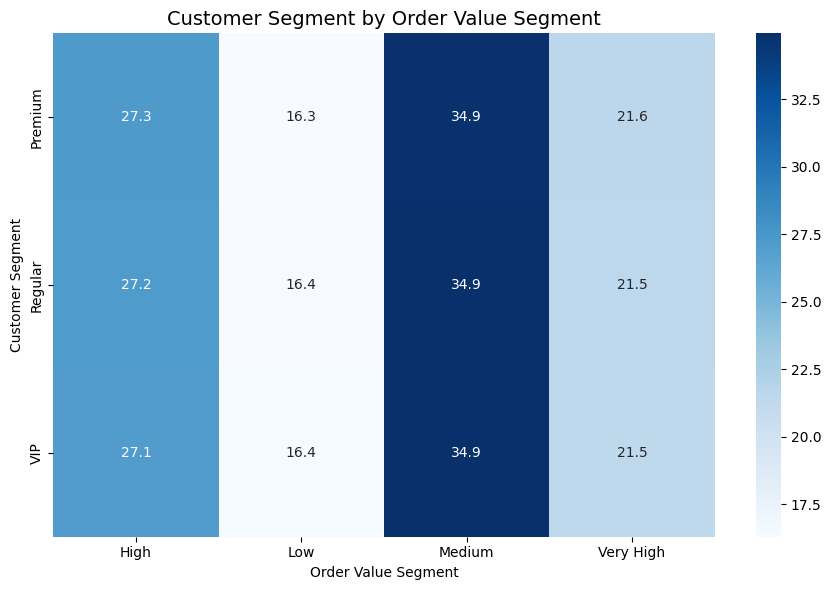

In [61]:
value_matrix = pd.crosstab(
    customer_df['customer_segment'],
    customer_df['order_value_segment'],
    normalize='index'
) * 100

plt.figure(figsize=(9, 6))

sns.heatmap(
    value_matrix,
    annot=True,
    fmt='.1f',
    cmap='Blues'
)

plt.title('Customer Segment by Order Value Segment', fontsize=14)
plt.xlabel('Order Value Segment')
plt.ylabel('Customer Segment')

plt.tight_layout()
plt.show()